In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','reject','pt1','pt2','y1','y2','phi1','phi2','nef','evid']
observabless1 = ['pts','bs','ws','rejects','pt1s','pt2s','y1s','y2s','phi1s','phi2s','nefs','evids']

In [4]:
df_all = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all0615_final.root', "MatchedTree"),\
              'reject<=0 and rejects<=0')

Separate into two samples. Sample 1 serves as embedding and sample 2 serves as pseudo-data

In [5]:
odd = []
even = []
for i in range(0, df_all.shape[0]):
    if (df_all.iloc[i]['evid'] % 2 == 0):
        even.append(i)
    else:
        odd.append(i)

In [6]:
df1_all = df_all.iloc[odd]
df2_all = df_all.iloc[even]
df1_all.shape[0],df2_all.shape[0]

(216914, 216641)

In [7]:
df1_allreco = applyCut(df1_all, 'pts>15 and bs!=-9')
df2_allreco = applyCut(df2_all, 'pts>15 and bs!=-9')
df1_alltruth = applyCut(df1_all, 'pt>5 and b!=-9')
df2_alltruth = applyCut(df2_all, 'pt>5 and b!=-9')

In [9]:
distance1 = []
distance2 = []
for i in range(0,df1_allreco.shape[0]):
    phi1small = min(df1_allreco.iloc[i]['phi1'], df1_allreco.iloc[i]['phi1s'])
    phi1large = max(df1_allreco.iloc[i]['phi1'], df1_allreco.iloc[i]['phi1s'])
    phi2small = min(df1_allreco.iloc[i]['phi2'], df1_allreco.iloc[i]['phi2s'])
    phi2large = max(df1_allreco.iloc[i]['phi2'], df1_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df1_allreco.iloc[i]['phi1'], df1_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df1_allreco.iloc[i]['y1']-df1_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df1_allreco.iloc[i]['y2']-df1_allreco.iloc[i]['y2s'])**2))
df1_allreco['distance1'] = distance1
df1_allreco['distance2'] = distance2

/tmp/ipykernel_573727/2553912299.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1_allreco['distance1'] = distance1
/tmp/ipykernel_573727/2553912299.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1_allreco['distance2'] = distance2


In [10]:
distance1 = []
distance2 = []
for i in range(0,df2_allreco.shape[0]):
    phi1small = min(df2_allreco.iloc[i]['phi1'], df2_allreco.iloc[i]['phi1s'])
    phi1large = max(df2_allreco.iloc[i]['phi1'], df2_allreco.iloc[i]['phi1s'])
    phi2small = min(df2_allreco.iloc[i]['phi2'], df2_allreco.iloc[i]['phi2s'])
    phi2large = max(df2_allreco.iloc[i]['phi2'], df2_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df2_allreco.iloc[i]['phi1'], df2_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df2_allreco.iloc[i]['y1']-df2_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df2_allreco.iloc[i]['y2']-df2_allreco.iloc[i]['y2s'])**2))
df2_allreco['distance1'] = distance1
df2_allreco['distance2'] = distance2

/tmp/ipykernel_573727/3452015646.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2_allreco['distance1'] = distance1
/tmp/ipykernel_573727/3452015646.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2_allreco['distance2'] = distance2


Process sample 1

In [11]:
df1_allfake = applyCut(df1_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df1_match = applyCut(df1_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [12]:
df1_allreco_pts_array = [ df1_allreco[(df1_allreco.pts>15) & (df1_allreco.pts<20)],\
                       df1_allreco[(df1_allreco.pts>20) & (df1_allreco.pts<25)],\
                       df1_allreco[(df1_allreco.pts>25) & (df1_allreco.pts<30)],\
                       df1_allreco[(df1_allreco.pts>30) & (df1_allreco.pts<40)] ]

df1_match_pts_array = [ df1_match[(df1_match.pts>15) & (df1_match.pts<20)],\
                       df1_match[(df1_match.pts>20) & (df1_match.pts<25)],\
                       df1_match[(df1_match.pts>25) & (df1_match.pts<30)],\
                       df1_match[(df1_match.pts>30) & (df1_match.pts<40)],\
                       df1_match[(df1_match.pts>40) & (df1_match.pts<60)] ]

df1_allfake_pts_array = [ df1_allfake[(df1_allfake.pts>15) & (df1_allfake.pts<20)],\
                       df1_allfake[(df1_allfake.pts>20) & (df1_allfake.pts<25)],\
                       df1_allfake[(df1_allfake.pts>25) & (df1_allfake.pts<30)],\
                       df1_allfake[(df1_allfake.pts>30) & (df1_allfake.pts<40)],\
                       df1_allfake[(df1_allfake.pts>40) & (df1_allfake.pts<60)]  ]

In [13]:
rc1_allreco_bs_vs_pts_array = []
rc1_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df1_allreco_pts_array)):
    rc1_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[0])
    rc1_err_allreco_bs_vs_pts_array.append(getRcAndErr(df1_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df1_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df1_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df1_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df1_allfake_pts_array[i], 'bs')[1])

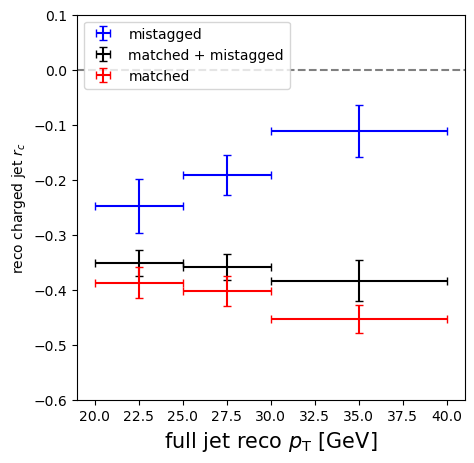

In [14]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc1_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc1_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [15]:
rc1_allreco_bs_vs_pts_array

[-0.3717949463196785,
 -0.35146738691280166,
 -0.35843858439446535,
 -0.3833318511086582]

In [16]:
rc1_err_allreco_bs_vs_pts_array

[0.01858087586999609,
 0.024298975749370205,
 0.024015272984028294,
 0.03663729963400824]

In [17]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [18]:
b1_fake_array = []
for i in range(0,5):
    df1_fake_pts = df1_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist(df1_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_fake_pts['ws'], density=True)
    b1_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [19]:
b1_fake_array

[array([0.62300651, 0.37699349]),
 array([0.62389367, 0.37610633]),
 array([0.59550049, 0.40449951]),
 array([0.55577674, 0.44422326]),
 array([0.70148676, 0.29851324])]

In [20]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]

In [21]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df1_match_pt_array[i], 'bs')[1])

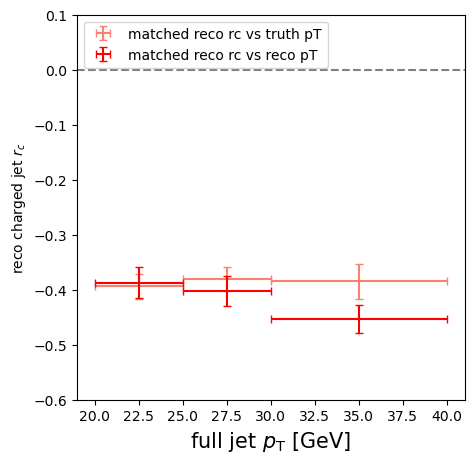

In [22]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco rc vs truth pT')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco rc vs reco pT')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [23]:
b1_match_array = []
for i in range(0,5):
    df1_match_pts = df1_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df1_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df1_match_pts['ws'], density=True)
    b1_match_array.append(y_reco/sum(y_reco))

In [24]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df1_allreco['pts'], bins=binedges, weights=df1_allreco['ws'])
match, _ = np.histogram(df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df1_allreco[(df1_allreco.pt!=-9) & (df1_allreco.b!=-9) & (df1_allreco.distance1<0.02) & (df1_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_573727/2916068059.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [25]:
eff4

array([       nan,        nan, 0.68928523, 0.74537315, 0.79043332,
       0.79518881, 0.72681976])

In [26]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.31071477, 0.25462685, 0.20956668, 0.20481119, 0.27318024])

Process sample 2

In [27]:
df2_allfake = applyCut(df2_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')
df2_match = applyCut(df2_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')

In [28]:
df2_allreco_pts_array = [ df2_allreco[(df2_allreco.pts>15) & (df2_allreco.pts<20)],\
                       df2_allreco[(df2_allreco.pts>20) & (df2_allreco.pts<25)],\
                       df2_allreco[(df2_allreco.pts>25) & (df2_allreco.pts<30)],\
                       df2_allreco[(df2_allreco.pts>30) & (df2_allreco.pts<40)] ]

df2_match_pts_array = [ df2_match[(df2_match.pts>15) & (df2_match.pts<20)],\
                       df2_match[(df2_match.pts>20) & (df2_match.pts<25)],\
                       df2_match[(df2_match.pts>25) & (df2_match.pts<30)],\
                       df2_match[(df2_match.pts>30) & (df2_match.pts<40)],\
                       df2_match[(df2_match.pts>40) & (df2_match.pts<60)] ]

df2_allfake_pts_array = [ df2_allfake[(df2_allfake.pts>15) & (df2_allfake.pts<20)],\
                       df2_allfake[(df2_allfake.pts>20) & (df2_allfake.pts<25)],\
                       df2_allfake[(df2_allfake.pts>25) & (df2_allfake.pts<30)],\
                       df2_allfake[(df2_allfake.pts>30) & (df2_allfake.pts<40)],\
                       df2_allfake[(df2_allfake.pts>40) & (df2_allfake.pts<60)] ]

In [29]:
rc2_allreco_bs_vs_pts_array = []
rc2_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df2_allreco_pts_array)):
    rc2_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[0])
    rc2_err_allreco_bs_vs_pts_array.append(getRcAndErr(df2_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df2_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df2_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df2_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df2_allfake_pts_array[i], 'bs')[1])

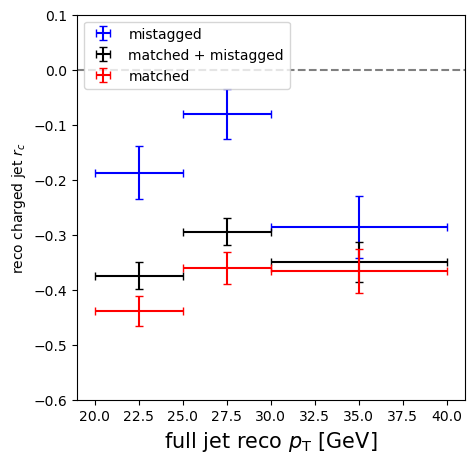

In [30]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_allfake_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_allfake_bs_vs_pts_array[1:-1], capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([22.5, 27.5, 35], rc2_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [31]:
df2_allreco_pts_array = [ df2_allreco[(df2_allreco.pts>15) & (df2_allreco.pts<20)],\
                       df2_allreco[(df2_allreco.pts>20) & (df2_allreco.pts<25)],\
                       df2_allreco[(df2_allreco.pts>25) & (df2_allreco.pts<30)],\
                       df2_allreco[(df2_allreco.pts>30) & (df2_allreco.pts<40)],\
                       df2_allreco[(df2_allreco.pts>40) & (df2_allreco.pts<60)] ]

In [32]:
b2_allreco_array = []
for i in range(0,5):
    df2_allreco_pts = df2_allreco_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df2_allreco_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df2_allreco_pts['ws'], density=True)
    b2_allreco_array.append(y_reco/sum(y_reco))

In [33]:
def subtractFake(data, fake_rate, fake_dist):
    corrected = (data - fake_rate * fake_dist)/(1 - fake_rate)
    return corrected

In [34]:
b2_fakesubtracted_array = []
rc_fakesubtracted_array = []
for i in range(0,5):
    print(i)
    print(b2_allreco_array[i])
    #print(getRc(data_array[i]))
    b2_fakesubtracted = subtractFake(b2_allreco_array[i], fake_rate_array[i], b1_fake_array[i])
    b2_fakesubtracted_array.append(b2_fakesubtracted)
    print(b2_fakesubtracted)
    nos = b2_fakesubtracted[0]
    nss = b2_fakesubtracted[1]
    rc_fakesubtracted = (nss-nos) / (nss+nos)
    rc_fakesubtracted_array.append(rc_fakesubtracted)

0
[0.6888664 0.3111336]
[0.71855461 0.28144539]
1
[0.68720192 0.31279808]
[0.70882865 0.29117135]
2
[0.6472863 0.3527137]
[0.66101622 0.33898378]
3
[0.67454914 0.32545086]
[0.70514051 0.29485949]
4
[0.69043579 0.30956421]
[0.68628221 0.31371779]


In [35]:
rc_fakesubtracted_array

[-0.43710922133830993,
 -0.4176572974115866,
 -0.32203243153664995,
 -0.41028102460775745,
 -0.3725644217515768]

In [36]:
reweight_array = []
for i in range(0,5):
    reweight_array.append((b2_fakesubtracted_array[i]/sum(b2_fakesubtracted_array[i]))/(b1_match_array[i]/sum(b1_match_array[i])))

In [37]:
reweight_array

[array([1.00603049, 0.98492662]),
 array([1.02218768, 0.94981072]),
 array([0.94240312, 1.13530293]),
 array([0.97037781, 1.07875138]),
 array([1.03197433, 0.93652325])]

Reweight sample 1

In [38]:
r = []
for i in range(0, df1_match.shape[0]):
    if (df1_match.iloc[i]['pts'] > 15 and df1_match.iloc[i]['pts'] < 20):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df1_match.iloc[i]['pts'] > 20 and df1_match.iloc[i]['pts'] < 25):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df1_match.iloc[i]['pts'] > 25 and df1_match.iloc[i]['pts'] < 30):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df1_match.iloc[i]['pts'] > 30 and df1_match.iloc[i]['pts'] < 40):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df1_match.iloc[i]['pts'] > 40 and df1_match.iloc[i]['pts'] < 60):
        if (df1_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df1_match.iloc[i]['pts'])
df1_match['r'] = r #

/tmp/ipykernel_573727/1025607542.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1_match['r'] = r #


In [39]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['ws'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['ws'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['ws'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        print(variance)
        variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [40]:
df1_match_pt_array = [ df1_match[(df1_match.pt>15) & (df1_match.pt<20)],\
                       df1_match[(df1_match.pt>20) & (df1_match.pt<25)],\
                       df1_match[(df1_match.pt>25) & (df1_match.pt<30)],\
                       df1_match[(df1_match.pt>30) & (df1_match.pt<40)],\
                       df1_match[(df1_match.pt>40) & (df1_match.pt<60)]  ]
df1_match_pts_array = [ df1_match[(df1_match.pts>15) & (df1_match.pts<20)],\
                       df1_match[(df1_match.pts>20) & (df1_match.pts<25)],\
                       df1_match[(df1_match.pts>25) & (df1_match.pts<30)],\
                       df1_match[(df1_match.pts>30) & (df1_match.pts<40)],\
                       df1_match[(df1_match.pts>40) & (df1_match.pts<60)] ]

In [41]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df1_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df1_match_pt_array[i], 'bs')[1])

0.000794774490406078
0.0001366280684189111
7.810203613202664e-05
0.0001787718303185576
0.002096206606778253
0.013498916774346875
[0.000794774490406078, 0.0001366280684189111, 7.810203613202664e-05, 0.0001787718303185576, 0.002096206606778253, 0.013498916774346875]
0.000794774490406078
0.0001366280684189111
7.810203613202664e-05
0.0001787718303185576
0.002096206606778253
0.013498916774346875
[0.000794774490406078, 0.0001366280684189111, 7.810203613202664e-05, 0.0001787718303185576, 0.002096206606778253, 0.013498916774346875]
0.0004783167407929316
4.9853477395337636e-05
9.464604549107154e-05
0.0011596096741857285
0.0472392787033196
[0.0004783167407929316, 4.9853477395337636e-05, 9.464604549107154e-05, 0.0011596096741857285, 0.0472392787033196]
0.0004783167407929316
4.9853477395337636e-05
9.464604549107154e-05
0.0011596096741857285
0.0472392787033196
[0.0004783167407929316, 4.9853477395337636e-05, 9.464604549107154e-05, 0.0011596096741857285, 0.0472392787033196]
0.00026967162879959987
6.2

Obtain sample 2 truth

In [42]:
df2_alltruth_pt_array = [ df2_alltruth[(df2_alltruth.pt>15) & (df2_alltruth.pt<20)],\
                       df2_alltruth[(df2_alltruth.pt>20) & (df2_alltruth.pt<25)],\
                       df2_alltruth[(df2_alltruth.pt>25) & (df2_alltruth.pt<30)],\
                       df2_alltruth[(df2_alltruth.pt>30) & (df2_alltruth.pt<40)] ]

In [43]:
rc2_truth_b_vs_pt_array = []
rc2_err_truth_b_vs_pt_array = []
for i in range(0, len(df2_alltruth_pt_array)):
    rc2_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[0])
    rc2_err_truth_b_vs_pt_array.append(getRcAndErr(df2_alltruth_pt_array[i], 'b')[1])

Check closure

In [63]:
rc_stat_err = np.array([0.0032768538529201106, 0.006688613461258784, 0.012425797722755979]) # use statistical uncertainty from data

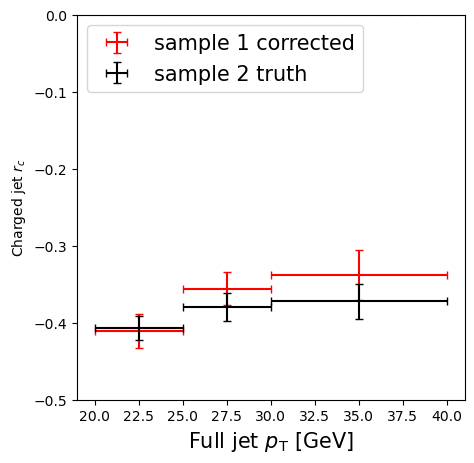

In [45]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.errorbar([22.5, 27.5, 35], rc2_truth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_truth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='sample 2 truth')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.5,0.)
plt.legend(loc='upper left', fontsize=15)

In [46]:
print(np.array(rc_match_bs_vs_pt_array[1:-1]) - np.array(rc2_truth_b_vs_pt_array[1:]))

[-0.00389305  0.02382277  0.03447145]


Obtain sample 1 truth

In [47]:
df1_alltruth_pt_array = [ df1_alltruth[(df1_alltruth.pt>15) & (df1_alltruth.pt<20)],\
                       df1_alltruth[(df1_alltruth.pt>20) & (df1_alltruth.pt<25)],\
                       df1_alltruth[(df1_alltruth.pt>25) & (df1_alltruth.pt<30)],\
                       df1_alltruth[(df1_alltruth.pt>30) & (df1_alltruth.pt<40)] ]

In [48]:
rc1_truth_b_vs_pt_array = []
rc1_err_truth_b_vs_pt_array = []
for i in range(0, len(df1_alltruth_pt_array)):
    rc1_truth_b_vs_pt_array.append(getRcAndErr(df1_alltruth_pt_array[i], 'b')[0])
    rc1_err_truth_b_vs_pt_array.append(getRcAndErr(df1_alltruth_pt_array[i], 'b')[1])

Check two samples have the same truth & reco to begin with

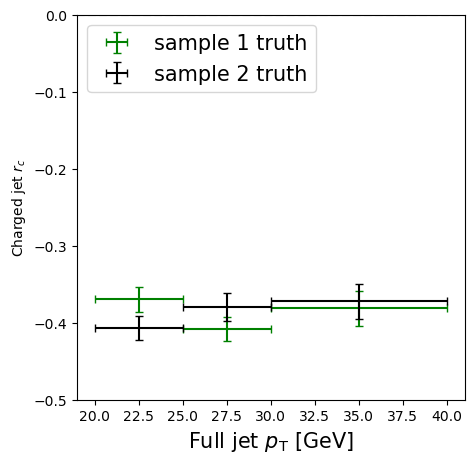

In [49]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc1_truth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc1_err_truth_b_vs_pt_array[1:], capsize=3, color='g', ls='none', label='sample 1 truth')
plt.errorbar([22.5, 27.5, 35], rc2_truth_b_vs_pt_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_truth_b_vs_pt_array[1:], capsize=3, color='k', ls='none', label='sample 2 truth')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.5,0.)
plt.legend(loc='upper left', fontsize=15)

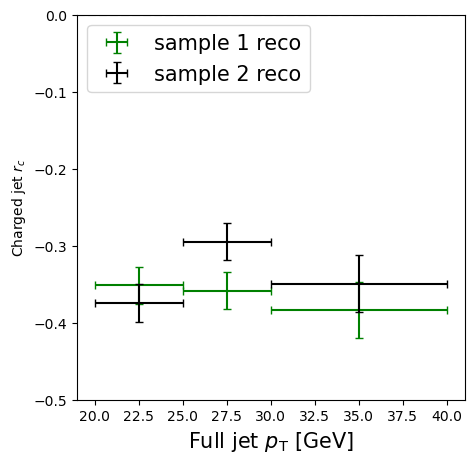

In [50]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([22.5, 27.5, 35], rc1_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc1_err_allreco_bs_vs_pts_array[1:], capsize=3, color='g', ls='none', label='sample 1 reco')
plt.errorbar([22.5, 27.5, 35], rc2_allreco_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc2_err_allreco_bs_vs_pts_array[1:], capsize=3, color='k', ls='none', label='sample 2 reco')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.5,0.)
plt.legend(loc='upper left', fontsize=15)